# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Computer Vision Lab** | Run all cells top to bottom (Runtime > Run all). Only edit `REG_NO` in the first code cell.

In [1]:
!pip -q install medmnist

## Personal Settings

In [2]:
# ====== ONLY EDIT THIS LINE: put your registration number ======
REG_NO = "029"
# ===============================================================

import re
digits = re.sub(r"\D", "", REG_NO)
SEED = int(digits[-2:])
LAST = int(digits[-1])
HOG_CELL = 8 if LAST % 2 == 0 else 16
GRID = 4 if LAST <= 4 else 6

import pandas as pd
pd.DataFrame({
    "Setting": ["Registration number", "Random seed", "HOG cell size", "SIFT grid size"],
    "Your value": [REG_NO, SEED, f"{HOG_CELL} x {HOG_CELL}", f"{GRID} x {GRID} grid ({GRID*GRID} keypoints)"]
})

,Setting,Your value
0,Registration number,029
1,Random seed,29
2,HOG cell size,16 x 16
3,SIFT grid size,6 x 6 grid (36 keypoints)


In [3]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, cv2, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
np.random.seed(SEED)
print("OpenCV:", cv2.__version__)

OpenCV: 5.0.0


# Q1. Data setup (3 marks)

In [4]:
from medmnist import BloodMNIST

CLASS_MAP = {1: "eosinophil", 5: "monocyte", 6: "neutrophil", 7: "platelet"}
ORIG_IDS = list(CLASS_MAP.keys())
NAMES = list(CLASS_MAP.values())
rng = np.random.RandomState(SEED)

def load_subset(split, n_per_class):
    ds = BloodMNIST(split=split, download=True, size=64)
    X = ds.imgs
    y = ds.labels.ravel()
    xs, ys = [], []
    for new_label, orig in enumerate(ORIG_IDS):
        ids = np.where(y == orig)[0]
        pick = rng.choice(ids, n_per_class, replace=False)
        xs.append(X[pick])
        ys += [new_label] * n_per_class
    return np.concatenate(xs), np.array(ys)

def to_gray128(imgs):
    out = []
    for im in imgs:
        g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY) if im.ndim == 3 else im
        out.append(cv2.resize(g, (128, 128), interpolation=cv2.INTER_LINEAR))
    return np.array(out, dtype=np.uint8)

Xtr_raw, ytr = load_subset("train", 100)
Xva_raw, yva = load_subset("val", 30)
Xte_raw, yte = load_subset("test", 30)

Xtr, Xva, Xte = to_gray128(Xtr_raw), to_gray128(Xva_raw), to_gray128(Xte_raw)

for name, X, y in [("train", Xtr, ytr), ("val", Xva, yva), ("test", Xte, yte)]:
    counts = {NAMES[i]: int(c) for i, c in enumerate(np.bincount(y, minlength=4))}
    print(f"{name:5s} | X shape: {X.shape} | y shape: {y.shape} | class counts: {counts}")

100%|██████████| 156M/156M [00:30<00:00, 5.17MB/s]


train | X shape: (400, 128, 128) | y shape: (400,) | class counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   | X shape: (120, 128, 128) | y shape: (120,) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  | X shape: (120, 128, 128) | y shape: (120,) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


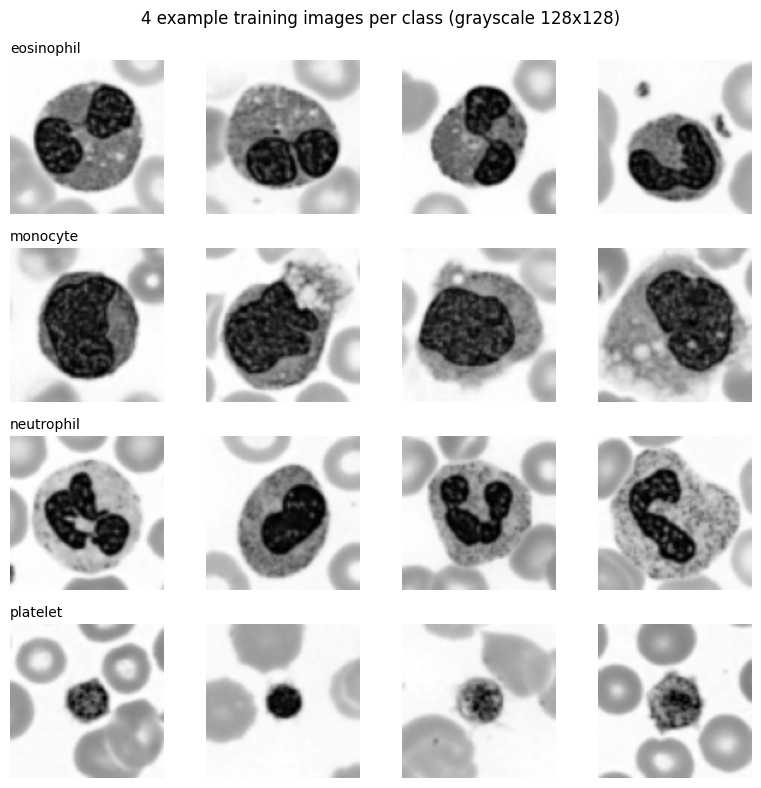

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    idx = np.where(ytr == r)[0][:4]
    for c in range(4):
        axes[r, c].imshow(Xtr[idx[c]], cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(NAMES[r], fontsize=10, loc="left")
plt.suptitle("4 example training images per class (grayscale 128x128)")
plt.tight_layout()
plt.show()

# Q2. HOG + SVM (6 marks)
## Q2a. HOG feature extraction and hand calculation

In [6]:
def hog_feat(img):
    return hog(img, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True)

def extract(X, fn):
    return np.array([fn(im) for im in X], dtype=np.float32)

Htr, Hva = extract(Xtr, hog_feat), extract(Xva, hog_feat)
print("HOG feature matrix (train):", Htr.shape)
print("HOG feature length from code:", Htr.shape[1])

n_cells = 128 // HOG_CELL
n_blocks = n_cells - 1
per_block = 2 * 2 * 9
manual = n_blocks * n_blocks * per_block
assert manual == Htr.shape[1]

display(Markdown(f'''
**Hand calculation of HOG feature length (cell = {HOG_CELL} x {HOG_CELL}):**

1. Cells per side = 128 / {HOG_CELL} = **{n_cells}** (so {n_cells} x {n_cells} = {n_cells*n_cells} cells)
2. Blocks are 2 x 2 cells and slide by 1 cell, so blocks per side = {n_cells} - 2 + 1 = **{n_blocks}** (so {n_blocks} x {n_blocks} = {n_blocks*n_blocks} blocks)
3. Values per block = 2 x 2 cells x 9 orientations = **{per_block}**
4. Total length = {n_blocks*n_blocks} blocks x {per_block} = **{manual}**

This matches the length printed by the code: **{Htr.shape[1]}**.
'''))

HOG feature matrix (train): (400, 1764)
HOG feature length from code: 1764



**Hand calculation of HOG feature length (cell = 16 x 16):**

1. Cells per side = 128 / 16 = **8** (so 8 x 8 = 64 cells)
2. Blocks are 2 x 2 cells and slide by 1 cell, so blocks per side = 8 - 2 + 1 = **7** (so 7 x 7 = 49 blocks)
3. Values per block = 2 x 2 cells x 9 orientations = **36**
4. Total length = 49 blocks x 36 = **1764**

This matches the length printed by the code: **1764**.


## Q2b. HOG pictures (one image per class)

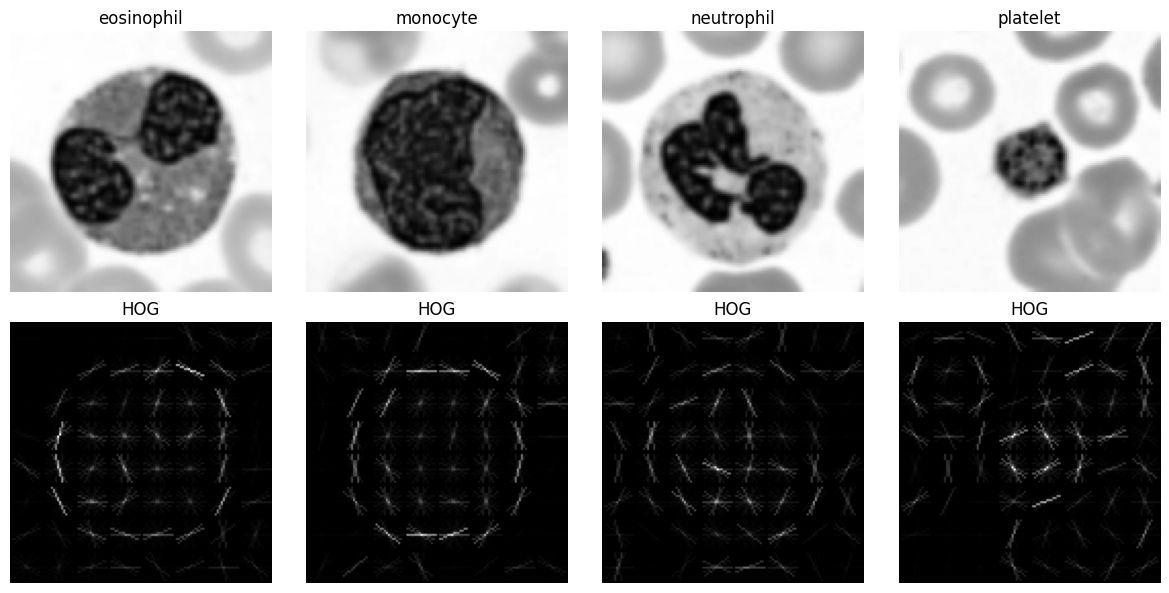

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for r in range(4):
    img = Xtr[np.where(ytr == r)[0][0]]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
                     cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() + 1e-9))
    axes[0, r].imshow(img, cmap="gray"); axes[0, r].set_title(NAMES[r]); axes[0, r].axis("off")
    axes[1, r].imshow(hog_img, cmap="gray"); axes[1, r].set_title("HOG"); axes[1, r].axis("off")
plt.tight_layout(); plt.show()

## Q2c. Train HOG + SVM (C chosen on validation set)

[HOG+SVM] validation accuracy for each C:
   C = 0.1   -> val acc = 0.7250
   C = 1     -> val acc = 0.7250
   C = 10    -> val acc = 0.7250
[HOG+SVM] Chosen C = 0.1
[HOG+SVM] Validation accuracy: 0.7250
[HOG+SVM] Validation macro-F1: 0.7266
[HOG+SVM] Confusion matrix (rows = true, cols = predicted; order: ['eosinophil', 'monocyte', 'neutrophil', 'platelet']):
[[17  9  4  0]
 [ 5 20  4  1]
 [ 8  0 22  0]
 [ 1  1  0 28]]


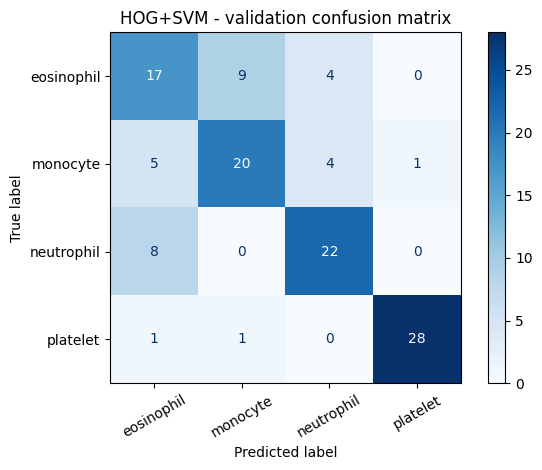

In [8]:
C_GRID = [0.1, 1, 10]

def fit_svm(Ftr, ytr, Fva, yva, label):
    best = None
    rows = []
    for C in C_GRID:
        m = make_pipeline(StandardScaler(), LinearSVC(C=C, max_iter=20000, random_state=SEED))
        m.fit(Ftr, ytr)
        acc = accuracy_score(yva, m.predict(Fva))
        rows.append((C, acc))
        if best is None or acc > best[1]:
            best = (C, acc, m)
    print(f"[{label}] validation accuracy for each C:")
    for C, acc in rows:
        print(f"   C = {C:<5} -> val acc = {acc:.4f}")
    print(f"[{label}] Chosen C = {best[0]}")
    return best[2], best[0]

def report(model, F, y, label):
    pred = model.predict(F)
    acc = accuracy_score(y, pred)
    f1 = f1_score(y, pred, average="macro")
    cm = confusion_matrix(y, pred, labels=range(4))
    print(f"[{label}] Validation accuracy: {acc:.4f}")
    print(f"[{label}] Validation macro-F1: {f1:.4f}")
    print(f"[{label}] Confusion matrix (rows = true, cols = predicted; order: {NAMES}):")
    print(cm)
    ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(f"{label} - validation confusion matrix"); plt.tight_layout(); plt.show()
    return cm, acc, f1

hog_model, hog_C = fit_svm(Htr, ytr, Hva, yva, "HOG+SVM")
cm_hog, hog_val_acc, hog_val_f1 = report(hog_model, Hva, yva, "HOG+SVM")

# Q3. SIFT + SVM (7 marks)
## Q3a. Normal SIFT detection on training images

Average keypoints per image : 70.04
Minimum keypoints per image : 8
Maximum keypoints per image : 229
Images with zero keypoints  : 0 (out of 400)


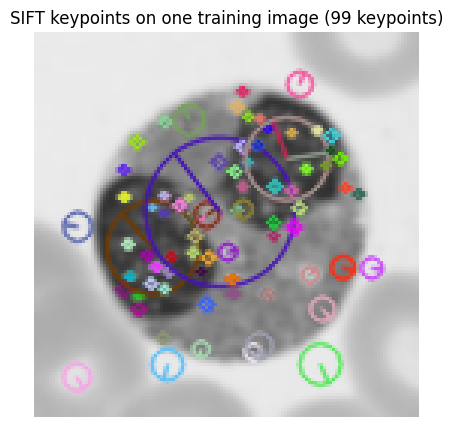

In [9]:
sift = cv2.SIFT_create()
kp_counts, kp_first = [], None
for i, im in enumerate(Xtr):
    kps, des = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps))
    if i == 0:
        kp_first = kps

kp_counts = np.array(kp_counts)
print(f"Average keypoints per image : {kp_counts.mean():.2f}")
print(f"Minimum keypoints per image : {kp_counts.min()}")
print(f"Maximum keypoints per image : {kp_counts.max()}")
print(f"Images with zero keypoints  : {(kp_counts == 0).sum()} (out of {len(kp_counts)})")

vis = cv2.drawKeypoints(Xtr[0], kp_first, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"SIFT keypoints on one training image ({len(kp_first)} keypoints)"); plt.show()

**Why is a different number of keypoints per image a problem for an SVM?**
An SVM needs every image to be a feature vector of the same length, but with normal SIFT each image gives a different number of 128-dimensional descriptors, so the vectors have different lengths and cannot be fed to the SVM.

## Q3b. Fix: fixed grid of keypoints

SIFT-grid feature matrix (train): (400, 4608)
SIFT-grid feature length from code: 4608



**Hand calculation of SIFT-grid feature length (6 x 6 grid):**

1. Grid points = 6 x 6 = **36** keypoints (size 32, evenly spread over 128 x 128)
2. Each SIFT descriptor has **128** values (4 x 4 spatial bins x 8 orientations)
3. Total length = 36 x 128 = **4608**

This matches the length printed by the code: **4608**.


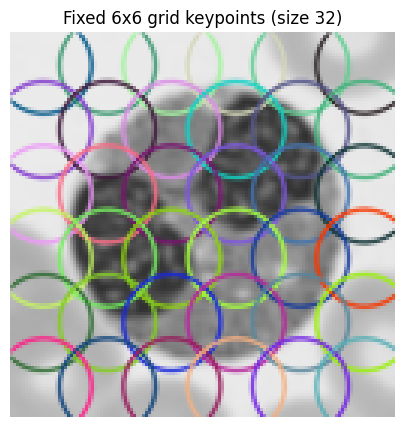

In [10]:
sift_grid = cv2.SIFT_create()
KP_SIZE = 32
pos = (np.arange(GRID) + 0.5) * (128 / GRID)       # centres of the grid cells

def make_grid_kps():
    return [cv2.KeyPoint(float(x), float(y), KP_SIZE) for y in pos for x in pos]

def sift_grid_feat(img):
    kps = make_grid_kps()
    kps, des = sift_grid.compute(img, kps)
    n = GRID * GRID
    out = np.zeros((n, 128), dtype=np.float32)      # safe fixed size
    if des is not None:
        m = min(n, des.shape[0])
        out[:m] = des[:m]
    return out.ravel()

Str, Sva = extract(Xtr, sift_grid_feat), extract(Xva, sift_grid_feat)
print("SIFT-grid feature matrix (train):", Str.shape)
print("SIFT-grid feature length from code:", Str.shape[1])

display(Markdown(f'''
**Hand calculation of SIFT-grid feature length ({GRID} x {GRID} grid):**

1. Grid points = {GRID} x {GRID} = **{GRID*GRID}** keypoints (size {KP_SIZE}, evenly spread over 128 x 128)
2. Each SIFT descriptor has **128** values (4 x 4 spatial bins x 8 orientations)
3. Total length = {GRID*GRID} x 128 = **{GRID*GRID*128}**

This matches the length printed by the code: **{Str.shape[1]}**.
'''))

vis = cv2.drawKeypoints(Xtr[0], make_grid_kps(), None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"Fixed {GRID}x{GRID} grid keypoints (size {KP_SIZE})"); plt.show()

## Q3c. Train SIFT + SVM (C chosen on validation set)

[SIFT+SVM] validation accuracy for each C:
   C = 0.1   -> val acc = 0.7583
   C = 1     -> val acc = 0.7583
   C = 10    -> val acc = 0.7583
[SIFT+SVM] Chosen C = 0.1
[SIFT+SVM] Validation accuracy: 0.7583
[SIFT+SVM] Validation macro-F1: 0.7532
[SIFT+SVM] Confusion matrix (rows = true, cols = predicted; order: ['eosinophil', 'monocyte', 'neutrophil', 'platelet']):
[[15  7  8  0]
 [ 3 24  2  1]
 [ 7  1 22  0]
 [ 0  0  0 30]]


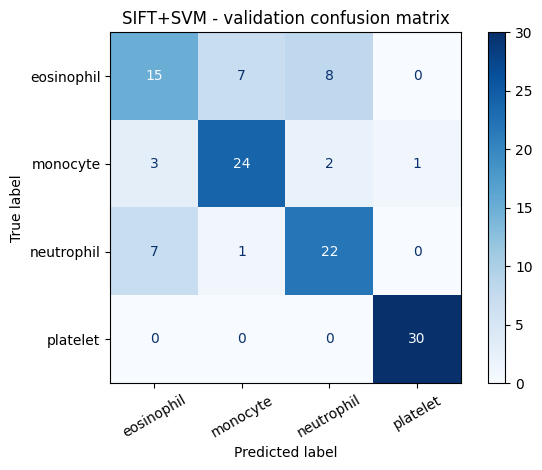

In [11]:
sift_model, sift_C = fit_svm(Str, ytr, Sva, yva, "SIFT+SVM")
cm_sift, sift_val_acc, sift_val_f1 = report(sift_model, Sva, yva, "SIFT+SVM")

# Q4. Robustness (6 marks)
## Q4a. Prediction (written before running the test)
**Rotation:** I think **HOG + SVM** will lose more accuracy under rotation, because HOG stores gradient orientations in fixed bins at fixed cell positions, so rotating the image shifts both the orientation histograms and the spatial layout of the whole feature vector. The grid-SIFT descriptors are computed over larger 32 x 32 patches that average a lot of local structure, so they should change less for a 20 degree turn.

**Noise:** I think **HOG + SVM** will lose more accuracy under Gaussian noise, because HOG works on small cells (raw pixel gradients), and noise creates many random strong gradients. SIFT first smooths the image with Gaussian filtering and pools over a bigger patch, which suppresses noise.

## Q4b. Evaluation on the test set (models are frozen, test set used only here)

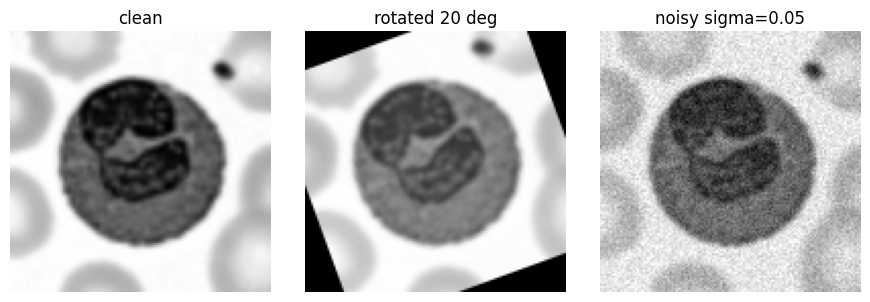

Test accuracy (fraction, 120 test images):


,Clean accuracy,Rotated accuracy,Noisy accuracy
Model,,,
HOG + SVM,0.7250,0.5833,0.2500
SIFT + SVM,0.7667,0.5000,0.7667


,Clean accuracy (%),Rotated accuracy (%),Noisy accuracy (%)
Model,,,
HOG + SVM,72.50,58.33,25.00
SIFT + SVM,76.67,50.00,76.67


In [12]:
def rotate20(img):
    M = cv2.getRotationMatrix2D((63.5, 63.5), 20, 1.0)
    return cv2.warpAffine(img, M, (128, 128), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

noise_rng = np.random.RandomState(SEED)
def add_noise(img, sigma=0.05):
    x = img.astype(np.float32) / 255.0
    x = x + noise_rng.normal(0.0, sigma, x.shape)
    return (np.clip(x, 0, 1) * 255).round().astype(np.uint8)

Xte_rot = np.array([rotate20(im) for im in Xte])
Xte_noisy = np.array([add_noise(im) for im in Xte])   # change applied BEFORE feature extraction

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, t in zip(axes, [Xte[0], Xte_rot[0], Xte_noisy[0]], ["clean", "rotated 20 deg", "noisy sigma=0.05"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

def test_acc(model, fn):
    out = {}
    for case, X in [("Clean", Xte), ("Rotated", Xte_rot), ("Noisy", Xte_noisy)]:
        out[case] = accuracy_score(yte, model.predict(extract(X, fn)))
    return out

res_hog = test_acc(hog_model, hog_feat)
res_sift = test_acc(sift_model, sift_grid_feat)

table = pd.DataFrame({
    "Model": ["HOG + SVM", "SIFT + SVM"],
    "Clean accuracy": [res_hog["Clean"], res_sift["Clean"]],
    "Rotated accuracy": [res_hog["Rotated"], res_sift["Rotated"]],
    "Noisy accuracy": [res_hog["Noisy"], res_sift["Noisy"]],
}).set_index("Model")
print("Test accuracy (fraction, 120 test images):")
display((table).round(4))
display((table * 100).round(2).add_suffix(" (%)"))

## Q4c. Was my prediction correct?

In [13]:
drop = lambda r: ((r["Clean"] - r["Rotated"]) * 100, (r["Clean"] - r["Noisy"]) * 100)
h_rot, h_noi = drop(res_hog)
s_rot, s_noi = drop(res_sift)
rot_ok = h_rot > s_rot
noi_ok = h_noi > s_noi

def verdict(ok): return "correct" if ok else "wrong"
overall = ("fully correct" if rot_ok and noi_ok else
           "partly correct" if (rot_ok or noi_ok) else "wrong")

display(Markdown(f'''
**Accuracy drops from the table (percentage points, clean minus changed):**
HOG: rotation {h_rot:.2f}, noise {h_noi:.2f} | SIFT: rotation {s_rot:.2f}, noise {s_noi:.2f}

1. For **rotation** I predicted HOG would lose more; HOG lost {h_rot:.2f} points and SIFT lost {s_rot:.2f} points, so this part of my prediction was **{verdict(rot_ok)}**.
2. For **noise** I predicted HOG would lose more; HOG lost {h_noi:.2f} points and SIFT lost {s_noi:.2f} points, so this part was **{verdict(noi_ok)}**.
3. Overall my prediction was **{overall}**; the clean accuracies were {res_hog["Clean"]*100:.2f}% (HOG) and {res_sift["Clean"]*100:.2f}% (SIFT), and with only 120 test images one image changes accuracy by about 0.83 points, so small differences should be read with care.
'''))


**Accuracy drops from the table (percentage points, clean minus changed):**
HOG: rotation 14.17, noise 47.50 | SIFT: rotation 26.67, noise 0.00

1. For **rotation** I predicted HOG would lose more; HOG lost 14.17 points and SIFT lost 26.67 points, so this part of my prediction was **wrong**.
2. For **noise** I predicted HOG would lose more; HOG lost 47.50 points and SIFT lost 0.00 points, so this part was **correct**.
3. Overall my prediction was **partly correct**; the clean accuracies were 72.50% (HOG) and 76.67% (SIFT), and with only 120 test images one image changes accuracy by about 0.83 points, so small differences should be read with care.


# Q5. Short answers and AI log (3 marks)
## Q5a. Short answers
**(a) Why does HOG use block normalisation?**
The gradient strength in a cell changes with lighting, contrast and staining intensity. HOG groups cells into overlapping blocks and normalises each block, so the descriptor depends on the relative gradient pattern rather than absolute brightness. This makes the features more stable under illumination and contrast changes.

**(b) Why is it wrong to choose C using the test set?**
If C is picked using the test set, the test data influences the model, so the test accuracy becomes optimistic and is no longer an honest estimate of performance on new data. The validation set is for tuning, and the test set must be kept untouched until the final evaluation.

## Q5b. Most confused classes

In [14]:
def top_pair(cm):
    off = cm.copy().astype(int)
    np.fill_diagonal(off, 0)
    sym = off + off.T
    iu = np.triu_indices(4, 1)
    k = np.argmax(sym[iu])
    i, j = iu[0][k], iu[1][k]
    return NAMES[i], NAMES[j], int(sym[i, j])

ph = top_pair(cm_hog); ps = top_pair(cm_sift); pb = top_pair(cm_hog + cm_sift)
print(f"HOG  : most confused pair = {ph[0]} <-> {ph[1]} ({ph[2]} validation mistakes)")
print(f"SIFT : most confused pair = {ps[0]} <-> {ps[1]} ({ps[2]} validation mistakes)")
print(f"Both : most confused pair = {pb[0]} <-> {pb[1]} ({pb[2]} validation mistakes combined)")

display(Markdown(f'''
The two classes my models confused most (using the validation confusion matrices above) were **{pb[0]}** and **{pb[1]}**.
Grayscale can make this harder because blood cell types are normally separated partly by stain colour (for example the colour of granules and the nucleus against the cytoplasm). Converting to one grey channel throws away that colour information, so cells with similar size, shape and texture can look almost the same to HOG and SIFT, which only use gradients.
'''))

HOG  : most confused pair = eosinophil <-> monocyte (14 validation mistakes)
SIFT : most confused pair = eosinophil <-> neutrophil (15 validation mistakes)
Both : most confused pair = eosinophil <-> neutrophil (27 validation mistakes combined)



The two classes my models confused most (using the validation confusion matrices above) were **eosinophil** and **neutrophil**.
Grayscale can make this harder because blood cell types are normally separated partly by stain colour (for example the colour of granules and the nucleus against the cytoplasm). Converting to one grey channel throws away that colour information, so cells with similar size, shape and texture can look almost the same to HOG and SIFT, which only use gradients.


## Q5c. AI log
| Prompt (one line) | What I changed | How I checked it was correct |
|---|---|---|
| "Build HOG + SVM and SIFT + SVM pipelines on BloodMNIST (4 classes) with my seed, HOG cell size and SIFT grid, plus rotation and noise tests." | Set my own registration number in `REG_NO`; checked the seed, HOG cell and grid values chosen from it; kept the chosen C from the validation printout. | Printed split shapes and class counts, compared the code feature lengths with my hand calculations (asserted equal), looked at the HOG pictures, grid keypoints picture and the rotated/noisy example images. |